# Researchly: article corpus, preprocessing and summaries (Question 3)

Five long articles from `research_corpus.zip` are loaded into a dataframe, denoised, and summarised in two ways.

In [1]:
import sys, re, glob, os, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from collections import Counter
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
warnings.filterwarnings("ignore")

sys.path.insert(0, "../deployment")
from text_utils import STOPWORDS
import simplemma

FIG = "../outputs/figures/"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 3.1 Corpus dataframe

In [2]:
files = sorted(glob.glob("../data/research_corpus/research_*.txt"),
               key=lambda p: int(re.search(r"_(\d+)\.txt", p).group(1)))
rows = []
for i, path in enumerate(files, start=1):
    with open(path, encoding="utf-8", errors="replace") as fh:
        txt = fh.read()
    rows.append({"doc_id": i, "file": os.path.basename(path), "text_raw": txt})
corpus = pd.DataFrame(rows)

# short names chosen by reading each article's opening lines
corpus["topic_label"] = ["mixed methods", "researcher reflexivity", "developmental research",
                         "Cronbach's alpha", "triangulation"]
corpus["first_line"] = corpus["text_raw"].str.strip().str.split("\n").str[0].str[:70]
corpus["chars_raw"] = corpus["text_raw"].str.len()
corpus["words_raw"] = corpus["text_raw"].str.split().str.len()
corpus[["doc_id", "file", "topic_label", "first_line", "chars_raw", "words_raw"]]

,doc_id,file,topic_label,first_line,chars_raw,words_raw
0,1,research_1.txt,mixed methods,The purposes of this article are to position m...,38160,5602
1,2,research_2.txt,researcher reflexivity,"Now I see it, now I don’t:",16104,2416
2,3,research_3.txt,developmental research,DEVELOPMENTAL RESEARCH: STUDIES OF,26154,3828
3,4,research_4.txt,Cronbach's alpha,Abstract,38950,5922
4,5,research_5.txt,triangulation,Denzin’s Paradigm Shift: Revisiting Triangulat...,26831,4027


In [3]:
print("articles:", len(corpus), "| total words:", corpus["words_raw"].sum())
print("empty texts:", (corpus["words_raw"] == 0).sum())
print("\nFirst 400 characters of article 4 (note the web page leftovers):\n")
print(corpus.loc[3, "text_raw"][:400])

articles: 5 | total words: 21795
empty texts: 0

First 400 characters of article 4 (note the web page leftovers):

Abstract
Cronbach’s alpha is a statistic commonly quoted by authors to demonstrate that tests and scales that have been constructed or adopted for research projects are fit for purpose. Cronbach’s alpha is regularly adopted in studies in science education: it was referred to in 69 different papers published in 4 leading science education journals in a single year (2015)—usually as a measure of rel


The dataframe has one row per article with the file name, the full text and basic counts (21,795 words in total). The `topic_label` column is a short name I wrote after reading each opening. The brief calls this an AI research collection, but the five articles are about research methods: mixed methods, researcher reflexivity, developmental research, Cronbach's alpha and triangulation. They are analysed as they are.

The raw text is plainly an extraction from PDFs and web pages. It has hard line breaks in mid-sentence, author and university lines, footnote digits stuck to full stops, curly quotes, and in article 4 a block of "Similar content being viewed by others" with titles of unrelated papers.

## 3.2 Preprocessing and denoising

In [4]:
BULLET = "@@B@@"
CHAR_MAP = {"‘": "'", "’": "'", "“": '"', "”": '"', "–": "-", "—": " - ",
            "…": "...", "©": " ", "•": BULLET, "﻿": "", "⇒": " ",
            "": BULLET, "": BULLET}
SIMILAR_BLOCK = re.compile(r"Similar content being viewed by others.*?(?=\n\s*Introduction)", re.S | re.I)
PAREN_CITE = re.compile(r"\s*\([^()]*?\b(?:1[5-9]|20)\d{2}[a-z]?\b[^()]*\)")   # (Smith & Jones, 1998, p. 4)
BRACKET_REF = re.compile(r"\s*\[\s*\d+(?:\s*[,-]\s*\d+)*\s*\]")                # [12], [3-5]
URL_EMAIL = re.compile(r"(https?://\S+|www\.\S+|\S+@\S+\.\S+)")
FOOTNOTE = re.compile(r"(?<=[a-z.,;)\"'])\d{1,2}(?=\s|$)")                     # 'dispute.1 From' -> 'dispute. From'
FOOTNOTE_LIST = re.compile(r"(?<=[.,;)])\d{1,2}(?:,\s*\d{1,2})+")               # 'philosophy.3, 4' -> 'philosophy.'
SECTION_NO = re.compile(r"^\s*\d+(\.\d+)+\s+")                                   # '41.1 INTRODUCTION'
BOILER = re.compile(r"(open access|chapter\s*$|all rights reserved|^keywords?\s*:|full size image|^(fig\.?|figure|table)\s*\d+"
                    r"|\b(university|college|department)\b.{0,40}$)", re.I)
DATE_LINE = re.compile(r"^\s*\d{1,2}\s+(january|february|march|april|may|june|july|august|september|october|november|december)\s+\d{4}\s*$", re.I)

def looks_like_heading(s):
    """Short line with no closing punctuation, or a title-case line."""
    words = s.split()
    closes = re.search(r"[.?!]['\")]*$", s)
    if closes:
        return False
    if len(words) <= 5:
        return True
    if s.endswith(":") and len(words) <= 8:
        return True
    if s.count(",") >= 3 and len(words) <= 12:                 # keyword list under an abstract
        return True
    caps = sum(w[0].isupper() for w in words if w[0].isalpha())
    return len(words) <= 14 and caps / len(words) >= 0.6

def denoise_article(text, log=None):
    """Return running prose: sentences intact, case and punctuation kept."""
    for k, v in CHAR_MAP.items():
        text = text.replace(k, v)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()     # drop accents and symbols
    text = SIMILAR_BLOCK.sub("\n", text)
    text = re.sub(r"-\n(?=[a-z])", "", text)                                          # re-join hyphenated line breaks
    kept = []
    for line in text.split("\n"):
        s = line.strip()
        if not s or re.fullmatch(r"\d+", s) or DATE_LINE.match(s):
            continue
        bullet = s.startswith(BULLET)
        s = s.replace(BULLET, "").strip()
        s = SECTION_NO.sub("", s)
        if not s:
            continue
        if BOILER.search(s) and len(s.split()) < 12:
            if log is not None: log.append(s)
            continue
        if not bullet and looks_like_heading(s):
            if log is not None: log.append(s)
            continue
        kept.append((". " + s[0].upper() + s[1:]) if bullet else s)       # a bullet starts a new sentence
    text = " ".join(kept)
    text = URL_EMAIL.sub(" ", text)
    text = PAREN_CITE.sub("", text)
    text = BRACKET_REF.sub("", text)
    text = FOOTNOTE_LIST.sub("", text)
    text = FOOTNOTE.sub("", text)
    text = re.sub(r"\s+([,.;:?!])", r"\1", text)
    text = re.sub(r"\(\s*\)", "", text)
    text = re.sub(r"([.?!])\s*\.\s+", r"\1 ", text)                         # '. . ' left by bullets
    return re.sub(r"\s+", " ", text).strip()


def drop_repeated_sentences(text, min_words=8):
    """Some files hold the same passage twice. Keep the first copy of every sentence."""
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z\"'(])", text)
    seen, out, removed = set(), [], 0
    for p in parts:
        key = re.sub(r"\W+", " ", p.lower()).strip()
        if len(key.split()) >= min_words:
            if key in seen:
                removed += 1
                continue
            seen.add(key)
        out.append(p)
    return " ".join(out), removed

In [5]:
dropped = {}
clean, reps = [], []
for _, r in corpus.iterrows():
    log = []
    txt, n_rep = drop_repeated_sentences(denoise_article(r["text_raw"], log))
    clean.append(txt); reps.append(n_rep)
    dropped[r["doc_id"]] = log
corpus["text_clean"] = clean
corpus["repeated_removed"] = reps
corpus["words_clean"] = corpus["text_clean"].str.split().str.len()
print(corpus[["doc_id", "topic_label", "words_raw", "words_clean", "repeated_removed"]].to_string(index=False))
print("\nSample of removed lines (article 3):", dropped[3][:8])
print("Sample of removed lines (article 4):", dropped[4][:8])
print("\nCitations left over (pattern '(... 19xx/20xx)'):", sum(len(re.findall(r"\([^()]*(?:19|20)\d{2}[^()]*\)", t)) for t in corpus.text_clean))
print("\nArticle 1, before:\n", corpus.loc[0, "text_raw"][1500:1900].replace("\n", "\\n"))
print("\nArticle 1, after:\n", corpus.loc[0, "text_clean"][1000:1400])

 doc_id            topic_label  words_raw  words_clean  repeated_removed
      1          mixed methods       5602         2573                74
      2 researcher reflexivity       2416         2168                 0
      3 developmental research       3828         3429                 0
      4       Cronbach's alpha       5922         5645                 0
      5          triangulation       4027         3516                 0

Sample of removed lines (article 3): ['DEVELOPMENTAL RESEARCH: STUDIES OF', 'INSTRUCTIONAL DESIGN AND DEVELOPMENT', 'Rita C. Richey', 'Wayne State University', 'James D. Klein', 'Arizona State University', 'Wayne A. Nelson', 'Southern Illinois University at Edwardsville']
Sample of removed lines (article 4): ['Abstract', 'Introduction', "The Use of Cronbach's Alpha in Science Education Studies", "The Frequency of Use of Cronbach's Alpha in Science Education", 'Describing the Significance of Alpha', "Characterising Values of Cronbach's Alpha", 'Fig. 1', 'f

In [6]:
DOMAIN_STOP = {"say", "make", "get", "give", "take", "come", "go", "see", "know", "include", "work", "way",
               "example", "different", "like", "need", "provide", "base", "number", "datum"}
ALL_STOP = STOPWORDS | DOMAIN_STOP
LEMMA_FIX = {"mixed": "mixed", "dissolving": "dissolve"}   # simplemma clips these

def tokenize(text):
    """Lowercase word tokens, stop words out, lemmatised."""
    out = []
    for tok in re.findall(r"[a-z]+", text.lower()):
        if tok in ALL_STOP or len(tok) < 3:
            continue
        lem = LEMMA_FIX.get(tok) or simplemma.lemmatize(tok, lang="en")
        if lem in ALL_STOP or len(lem) < 3:
            continue
        out.append(lem)
    return out

corpus["tokens"] = corpus["text_clean"].map(tokenize)
corpus["n_tokens"] = corpus["tokens"].str.len()
print(corpus[["doc_id", "n_tokens"]].T.to_string(header=False))
print("\nmost frequent lemmas overall:", Counter(t for ts in corpus.tokens for t in ts).most_common(15))

os.makedirs("../outputs", exist_ok=True)
save = corpus.copy(); save["tokens"] = save["tokens"].map(" ".join)
save.drop(columns=["text_raw"]).to_csv("../outputs/corpus_clean.csv", index=False)
corpus.drop(columns=["tokens"]).rename(columns={"text_raw": "text"})[["doc_id", "file", "topic_label", "text"]].to_csv("../outputs/corpus_dataframe.csv", index=False)

doc_id       1    2     3     4     5
n_tokens  1204  953  1532  2564  1620

most frequent lemmas overall: [('researcher', 113), ('alpha', 112), ('data', 104), ('method', 91), ('design', 91), ('development', 81), ('qualitative', 76), ('value', 73), ('triangulation', 71), ('instrument', 68), ('process', 65), ('report', 62), ('cronbach', 61), ('science', 57), ('knowledge', 56)]


The cleaner works in two stages. The first keeps readable sentences for the summarisers: it normalises quotes and accents, removes the web page block, title, author, affiliation, heading, keyword and figure-caption lines, turns bullets into sentence starts, strips author-year citations such as *(Seels & Richey, 1994, p. 127)*, bracketed references, footnote digits and URLs, and joins the hard-wrapped lines. The second stage lowercases, removes stop words and lemmatises, which is what topic modelling needs.

One finding came out of this step. The file for article 1 contains the whole article twice, so 74 repeated sentences were dropped and its length fell from 5,602 to 2,573 words. Without that step the same passages would count double in every frequency and topic. After cleaning, no parenthetical year citations remain.

Two imperfections remain. A hyphenated word broken across lines (*between-method*) is rejoined without its hyphen, and a few short table fragments in article 4 survive as sentences.

## 3.3 Summary of the first article (word-frequency extraction)

In [7]:
ABBREV = ["e.g.", "i.e.", "cf.", "vs.", "etc.", "et al.", "p.", "pp.", "Dr.", "Mr.", "No.", "Fig.", "viz."]

def split_sentences(text, min_words=10, max_words=50):
    """Split on sentence-final punctuation, keep mid-length sentences, drop exact repeats."""
    for a in ABBREV:
        text = text.replace(a, a.replace(".", "<dot>"))
    sents = re.split(r"(?<=[.!?])\s+(?=[A-Z\"'(])", text)
    seen, out = set(), []
    for s in (x.replace("<dot>", ".").strip() for x in sents):
        key = re.sub(r"\W+", " ", s.lower()).strip()
        if min_words <= len(s.split()) <= max_words and key not in seen:
            seen.add(key); out.append(s)
    return out

sent = {i: split_sentences(t) for i, t in zip(corpus.doc_id, corpus.text_clean)}
all_sent = {i: len(re.split(r"(?<=[.!?])\s+(?=[A-Z\"'(])", t)) for i, t in zip(corpus.doc_id, corpus.text_clean)}
print("sentences found      :", all_sent)
print("kept (10-50 words, unique):", {k: len(v) for k, v in sent.items()})

sentences found      : {1: 74, 2: 56, 3: 150, 4: 181, 5: 156}
kept (10-50 words, unique): {1: 58, 2: 38, 3: 137, 4: 154, 5: 142}


In [8]:
def frequency_summary(sentences, n=5):
    """Score each sentence by the average normalised frequency of its content words."""
    words = [w for s in sentences for w in tokenize(s)]
    freq = Counter(words); top = max(freq.values())
    norm = {w: c / top for w, c in freq.items()}
    scores = []
    for s in sentences:
        toks = tokenize(s)
        scores.append(sum(norm[t] for t in toks) / len(toks) if toks else 0)
    scores = np.array(scores)
    chosen = sorted(np.argsort(scores)[::-1][:n])           # keep original order
    return chosen, scores, freq

a1 = sent[1]
chosen1, scores1, freq1 = frequency_summary(a1, n=5)
print("Article 1 has %d usable sentences; summary keeps %d (%.0f%% of the words)\n" % (
    len(a1), len(chosen1), 100 * sum(len(a1[i].split()) for i in chosen1) / sum(len(s.split()) for s in a1)))
for rank, i in enumerate(chosen1, 1):
    print(f"{rank}. [sentence {i+1}, score {scores1[i]:.2f}] {a1[i]}\n")

Article 1 has 58 usable sentences; summary keeps 5 (6% of the words)

1. [sentence 18, score 0.39] We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful.

2. [sentence 23, score 0.47] Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research.

3. [sentence 26, score 0.38] For example, both quantitative and qualitative researchers use empirical observations to address research questions.

4. [sentence 34, score 0.71] For example, qualitative researchers should be free to use quantitative methods, and quantitative researchers should be free to use qualitative methods.

5. [sentence 38, score 0.36] That is, there is a tendency among some researchers to treat epistemology and method as being synonymous.



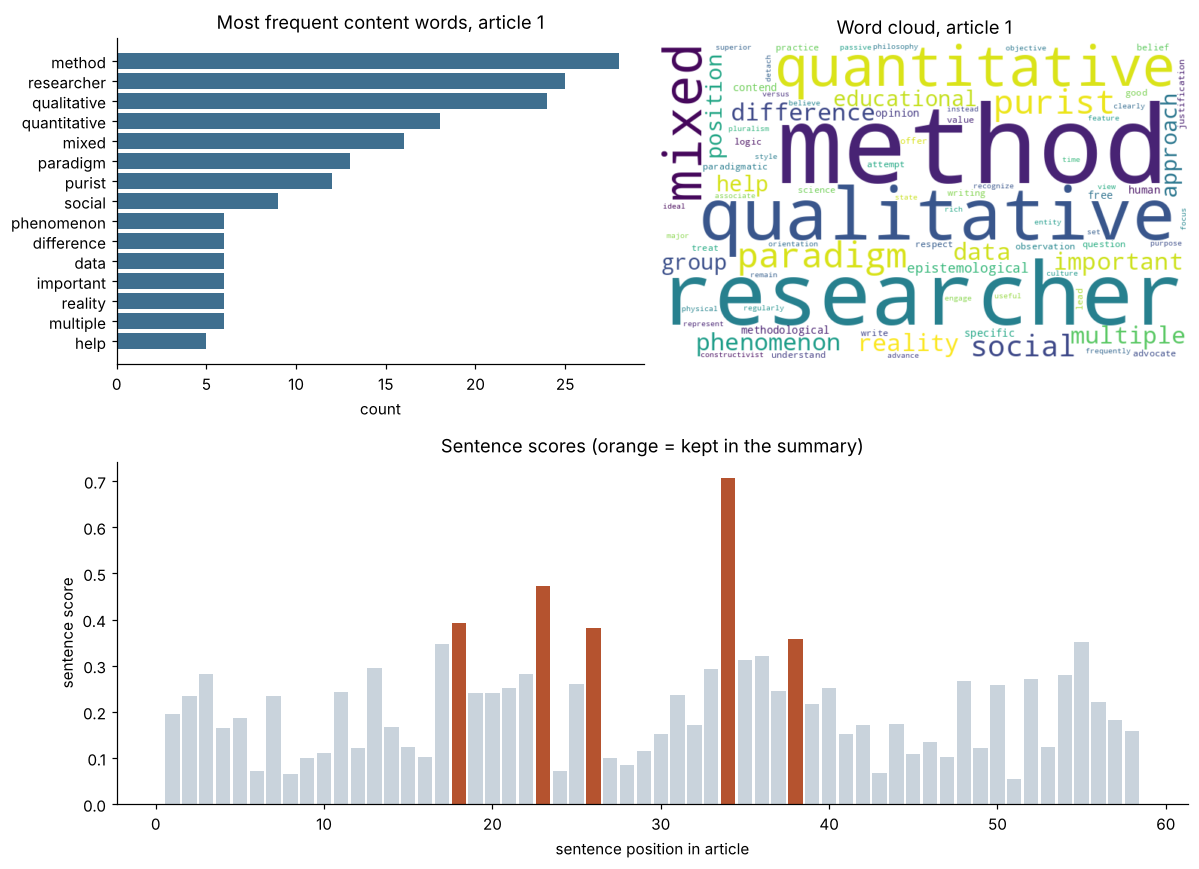

In [9]:
fig = plt.figure(figsize=(11, 8))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
ax1 = fig.add_subplot(gs[0, 0]); ax2 = fig.add_subplot(gs[0, 1]); ax3 = fig.add_subplot(gs[1, :])

top_words = freq1.most_common(15)[::-1]
ax1.barh([w for w, _ in top_words], [c for _, c in top_words], color="#3f6f8f")
ax1.set_title("Most frequent content words, article 1"); ax1.set_xlabel("count")

wc = WordCloud(width=700, height=420, background_color="white", colormap="viridis", max_words=80, random_state=1)
ax2.imshow(wc.generate_from_frequencies(dict(freq1)), interpolation="bilinear"); ax2.axis("off")
ax2.set_title("Word cloud, article 1")

colors = ["#b5532f" if i in set(chosen1) else "#c9d3dc" for i in range(len(a1))]
ax3.bar(range(1, len(a1) + 1), scores1, color=colors, width=0.85)
ax3.set_xlabel("sentence position in article"); ax3.set_ylabel("sentence score")
ax3.set_title("Sentence scores (orange = kept in the summary)")
plt.tight_layout(); plt.savefig(FIG + "q3_article1_summary.png", dpi=150); plt.show()

The method scores each sentence by the average normalised frequency of its content words and keeps the five best, in their original order. Sentences shorter than 10 or longer than 50 words are skipped, because short sentences otherwise win by default.

The five sentences cover the article's main claims: the field should move past the quantitative versus qualitative argument, mixed methods is a third paradigm that can bridge the two, and researchers in either tradition should be free to use the other's methods. The summary keeps about 6% of the words. The sentence-score chart shows that the winners are spread through the first two-thirds of the article, and that the highest score (0.71) belongs to the sentence about researchers borrowing each other's methods. The word frequencies (*method*, *researcher*, *qualitative*, *quantitative*, *mixed*, *paradigm*) match the summary.

## 3.4 Aggregate summary of articles 2 to 5 (TextRank)

In [10]:
def textrank(sentences, n=3):
    """Rank sentences with PageRank over a TF-IDF cosine-similarity graph."""
    vec = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None)
    M = vec.fit_transform(sentences)
    sim = cosine_similarity(M); np.fill_diagonal(sim, 0)
    g = nx.from_numpy_array(sim)
    pr = nx.pagerank(g, weight="weight")
    scores = np.array([pr[i] for i in range(len(sentences))])
    chosen = sorted(np.argsort(scores)[::-1][:n])
    return chosen, scores

rest = [i for i in corpus.doc_id if i != 1]
per_article = {}
for i in rest:
    ch, sc = textrank(sent[i], n=3)
    per_article[i] = (ch, sc)
    label = corpus.loc[corpus.doc_id == i, "topic_label"].item()
    print(f"--- Article {i} ({label})")
    for j in ch:
        print("  *", sent[i][j])
    print()

--- Article 2 (researcher reflexivity)
  * The main purpose of this article is to argue and illustrate that reflexivity in qualitative research is affected by whether the researcher is part of the researched and shares the participants' experience.
  * Consequently, researchers need to increasingly focus on self-knowledge and sensitivity; better understand the role of the self in the creation of knowledge; carefully self monitor the impact of their biases, beliefs, and personal experiences on their research; and maintain the balance between the personal and the universal.
  * This article discusses issues relative to reflexivity under varying types of researcher's personal experience with the world being studied and illustrates them using my own work.

--- Article 3 (developmental research)
  * While instructional development typically builds on previous research, developmental research attempts to produce the models and principles that guide the design, development, and evaluation pro

In [11]:
# Aggregate summary: pool the ten best sentences of every remaining article, then run TextRank once more
# over the pool, so sentences that echo themes found across articles rise to the top. At most two sentences
# per article are allowed, otherwise the largest cluster of similar sentences takes over the whole summary.
pool, origin = [], []
for i in rest:
    ch, sc = textrank(sent[i], n=10)
    for j in ch:
        pool.append(sent[i][j]); origin.append(i)
_, sc_all = textrank(pool, n=1)
picked, count = [], Counter()
for j in np.argsort(sc_all)[::-1]:
    if count[origin[j]] < 2:
        picked.append(j); count[origin[j]] += 1
    if len(picked) == 6:
        break
picked = sorted(picked, key=lambda j: (origin[j], j))
print("Aggregate summary of articles 2-5:\n")
for rank, j in enumerate(picked, 1):
    print(f"{rank}. (article {origin[j]}) {pool[j]}\n")
ch_all = picked

Aggregate summary of articles 2-5:

1. (article 3) While instructional development typically builds on previous research, developmental research attempts to produce the models and principles that guide the design, development, and evaluation processes.

2. (article 3) The second type of developmental study is oriented toward a general analysis of design, development, or evaluation processes, addressed either as a whole or in terms of a particular component.

3. (article 4) However, the literature also includes reports of the development of tests of student knowledge and understanding that cite Cronbach's alpha as an indicator of instrument quality.

4. (article 4) Adadan and Savasci call upon the Cronbach alpha statistic and relate it to both the terms reliability and internal consistency: The reliability of [the Nature of Solutions and Solubility - Diagnostic Instrument] was represented by using the Cronbach alpha coefficient.

5. (article 5) For example, the use of methodological tri

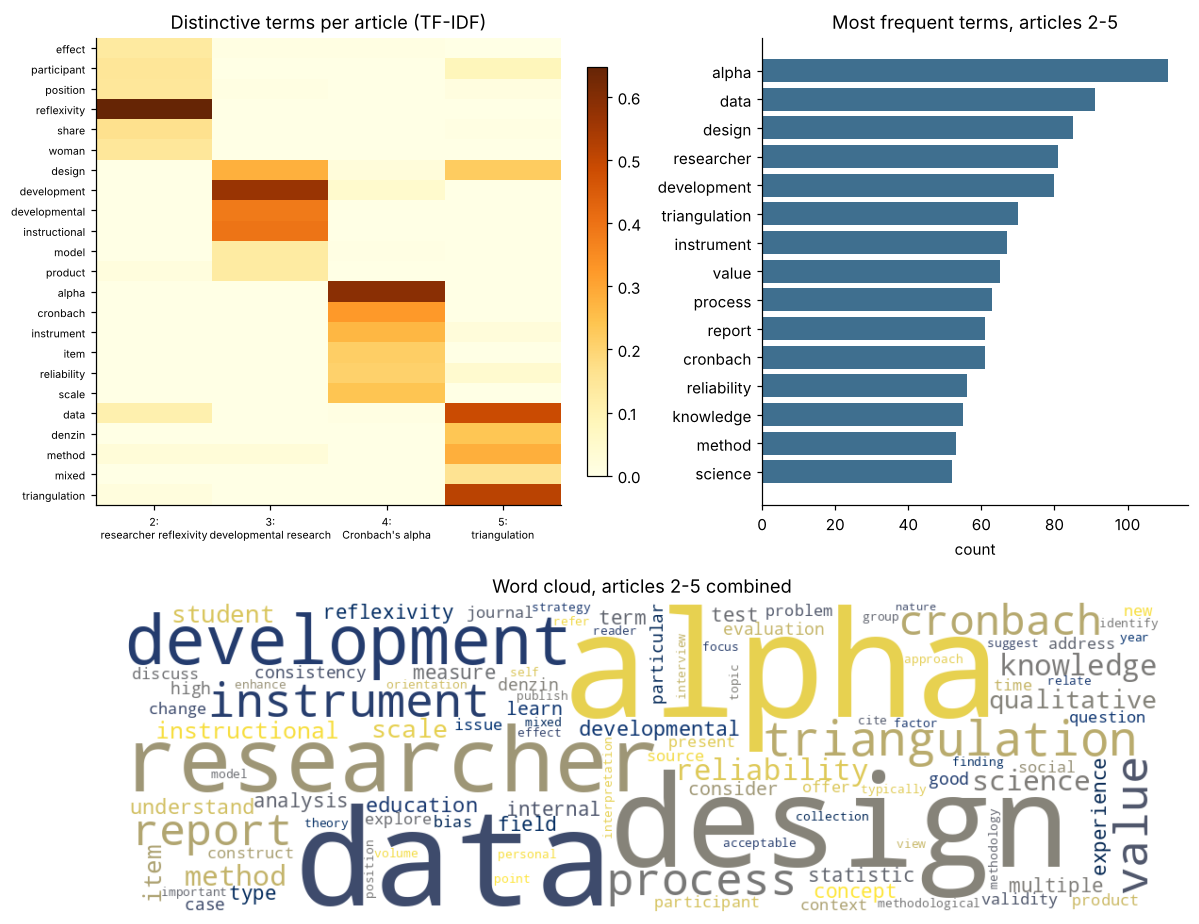

In [12]:
# Key terms: TF-IDF computed across the four articles, so a term scores high when one article leans on it.
docs = [" ".join(corpus.loc[corpus.doc_id == i, "tokens"].item()) for i in rest]
tv = TfidfVectorizer(max_df=0.75, min_df=1)
T = tv.fit_transform(docs); names = np.array(tv.get_feature_names_out())
top_idx = sorted({j for r in range(T.shape[0]) for j in np.argsort(T[r].toarray().ravel())[::-1][:6]})
heat = pd.DataFrame(T[:, top_idx].toarray().T, index=names[top_idx],
                    columns=[f"{i}: {corpus.loc[corpus.doc_id == i, 'topic_label'].item()}" for i in rest])
order = heat.values.argmax(axis=1).argsort(kind="stable")
heat = heat.iloc[order]

fig = plt.figure(figsize=(11, 8.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1.5, 1], width_ratios=[1.2, 1])
axh = fig.add_subplot(gs[0, 0]); axb = fig.add_subplot(gs[0, 1]); axw = fig.add_subplot(gs[1, :])

im = axh.imshow(heat.values, aspect="auto", cmap="YlOrBr")
axh.set_yticks(range(len(heat))); axh.set_yticklabels(heat.index, fontsize=7)
axh.set_xticks(range(heat.shape[1])); axh.set_xticklabels([c.replace(": ", ":\n") for c in heat.columns], fontsize=7)
axh.set_title("Distinctive terms per article (TF-IDF)"); plt.colorbar(im, ax=axh, fraction=0.04)


words_total = Counter(t for i in rest for t in corpus.loc[corpus.doc_id == i, "tokens"].item())
tw = words_total.most_common(15)[::-1]
axb.barh([w for w, _ in tw], [c for _, c in tw], color="#3f6f8f")
axb.set_title("Most frequent terms, articles 2-5"); axb.set_xlabel("count")

wc = WordCloud(width=1100, height=330, background_color="white", colormap="cividis", max_words=100, random_state=3)
axw.imshow(wc.generate_from_frequencies(dict(words_total)), interpolation="bilinear"); axw.axis("off")
axw.set_title("Word cloud, articles 2-5 combined")
plt.tight_layout(); plt.savefig(FIG + "q3_aggregate_summary.png", dpi=150); plt.show()

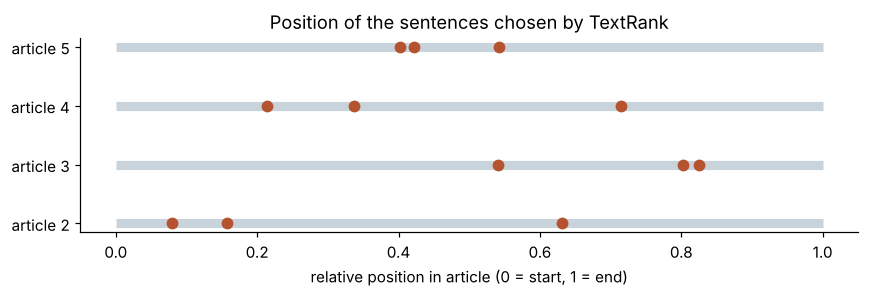

In [13]:
# Where in each article do the TextRank sentences come from?
fig, ax = plt.subplots(figsize=(8, 2.8))
for k, i in enumerate(rest):
    n = len(sent[i]); ch, sc = per_article[i]
    ax.hlines(k, 0, 1, color="#c9d3dc", lw=6)
    ax.scatter([j / n for j in ch], [k] * len(ch), color="#b5532f", zorder=3, s=45)
ax.set_yticks(range(len(rest))); ax.set_yticklabels([f"article {i}" for i in rest])
ax.set_xlabel("relative position in article (0 = start, 1 = end)"); ax.set_title("Position of the sentences chosen by TextRank")
plt.tight_layout(); plt.savefig(FIG + "q3_textrank_positions.png", dpi=150); plt.show()

TextRank builds a graph in which sentences are nodes and TF-IDF cosine similarity gives the edge weights, then ranks the nodes with PageRank. Each article gets three sentences. For the aggregate, the ten best sentences of every article were pooled, ranked again, and capped at two per article. Without the cap, article 5 supplied four of the six sentences, because its sentences are the most similar to one another and PageRank rewards that.

The resulting six sentences describe developmental research and its two types of study, the use of Cronbach's alpha as an indicator of instrument quality, and methodological triangulation. The reflexivity article does not appear in the aggregate, since its sentences are less similar to the rest, although it does have its own per-article summary. The heatmap shows that each article has its own distinctive vocabulary (*reflexivity*; *instructional*, *developmental*; *alpha*, *cronbach*; *triangulation*, *denzin*), and the combined counts are dominated by *alpha*, *data*, *design* and *researcher*.